# Lesson 5 — Sarsa, Expected Sarsa and Q-learning

*Chapter I. RL foundations and tabular methods · Section 5 of the lecture notes*

**Foundations:** Silver Lecture 5; Sutton–Barto §§5.3–5.4, 6.4–6.7.

> **Learning goal.** Compute the three targets and recognize the target policy/behavior policy; state correctly the scope of the tabular Q-learning guarantee.

> **How to read this notebook.** Markdown cells are the lecture, translated to English without changing its content. Boxes that start with **Code** map it to `td_control.py` (one base class `TDControlAgent`; `Sarsa`, `ExpectedSarsa`, `QLearning`, `DoubleQLearning` differ only in `target`), `experiment_cliff_walking.py` (Sutton–Barto Example 6.6) and `maximization_bias.py`.

In [1]:
%matplotlib inline
import inspect
import numpy as np
import matplotlib.pyplot as plt

from rlcore import TabularPolicy, cliff_walking
from td_control import EpsilonSchedule, ExpectedSarsa, QLearning, Sarsa, worked_example
from maximization_bias import single_and_double_estimates
import experiment_cliff_walking

## 1. Quick intuition

Control both learns value and uses value to change the policy. Sarsa evaluates the behavior currently being performed, including exploration. Q-learning backs up according to the best action at the next step even if the data is generated by another policy. This difference lies in the target, not only in how the current action is chosen. [Silver, Lecture 5]

## 2. The problem being solved

Input: online transitions or data with appropriate coverage; output: a table $Q$ and the policy derived from it. The behavior $\mu$ collects data; the target $\pi$ is the policy whose value we want to learn. On-policy uses the same policy for both roles; off-policy allows them to differ. The control objective is the return; the TD squared error, if used to fit a critic, is only a means of learning.

> **Code.** In every agent the behavior $\mu$ is `EpsilonGreedyPolicy(Q, epsilon)`. The update is shared by all agents; only the target differs:

In [2]:
from td_control import TDControlAgent
print(inspect.getsource(TDControlAgent.update))

    def update(self, s: int, a: int, r: float, s_next: int, a_next: int | None, terminal: bool) -> float:
        """Correct exactly one table entry; returns the TD error y - Q(s, a)."""
        delta = self.target(r, s_next, a_next, terminal) - self.Q[s, a]
        self.Q[s, a] += self.alpha * delta
        return delta



## 3. Core idea and formulas

$$Q(S_t,A_t) \leftarrow Q(S_t,A_t) + \alpha[R_{t+1} + \gamma Q(S_{t+1},A_{t+1}) - Q(S_t,A_t)]. \tag{15}$$

Inside the square brackets is the TD error for the pair $(S_t, A_t)$. The target uses $Q(S_{t+1}, A_{t+1})$, where $A_{t+1}$ is the action actually sampled from the policy being evaluated. Therefore an exploratory action at the next step also enters the target. The name Sarsa recalls the data tuple $S_t, A_t, R_{t+1}, S_{t+1}, A_{t+1}$. At a terminal there is no future action-value to bootstrap; the target is only the reward. The update only corrects the current pair in the table.

$$y = R_{t+1} + \gamma \sum_a \pi(a \mid S_{t+1}) Q(S_{t+1},a). \tag{16}$$

Instead of waiting to know one sampled $A_{t+1}$, we average the next-action values according to $\pi(a \mid S_{t+1})$. **Which randomness is removed?** The randomness of choosing the next action is computed as an expectation; the next state/reward are still samples. $y$ is the target, not the new value yet: use $Q(S_t,A_t) \leftarrow Q(S_t,A_t) + \alpha[y - Q(S_t,A_t)]$. The terminal has $y = R_{t+1}$.

$$Q(S_t,A_t) \leftarrow Q(S_t,A_t) + \alpha[R_{t+1} + \gamma \max_a Q(S_{t+1},a) - Q(S_t,A_t)]. \tag{17}$$

The target asks: **at the next state, if from there we choose the action with the largest estimate, what would the outcome be?** Because it uses the max, it does not need the exploratory action that the behavior will actually choose at the next step. This is what makes Q-learning off-policy. The max here uses the $Q$ being learned, so it can choose an overestimated action; it is not $q_*$ yet. At a terminal, drop the bootstrap part and use only the reward.

> **Code.** The three `target` methods side by side, each one line of Eqs. (15)–(17):

In [3]:
for cls in (Sarsa, ExpectedSarsa, QLearning):
    print(inspect.getsource(cls.target))

    def target(self, r, s_next, a_next, terminal):
        return r if terminal else r + self.gamma * self.Q[s_next, a_next]

    def target(self, r, s_next, a_next, terminal):
        return r if terminal else r + self.gamma * self.target_probs(s_next) @ self.Q[s_next]

    def target(self, r, s_next, a_next, terminal):
        return r if terminal else r + self.gamma * self.Q[s_next].max()



**Why is Q-learning off-policy?** After a real transition, the target assumes the future action is greedy with respect to $Q$. The behavior may still choose exploratory actions. Tabular one-step Q-learning does not need an action importance ratio: after conditioning on $(s,a)$, the next-transition sample still follows the dynamics of the environment. This does not turn data lacking coverage into sufficient data, nor does it exempt every actor–critic from correction.

**Convergence conditions.** A finite stationary MDP, bounded reward, $\gamma < 1$, every state–action visited infinitely often, and separate step sizes for each pair whose sum is infinite but whose sum of squares is finite are the standard sufficient conditions for tabular Q-learning. Sarsa control additionally needs appropriate policy improvement/exploration, for example GLIE together with the step-size conditions. A decaying $\epsilon$ schedule does not by itself prove that every pair has been visited enough. [Sutton–Barto §6.5; Silver Lecture 5]

> **Code.** `EpsilonSchedule.constant(0.1)` keeps exploring forever; `EpsilonSchedule.glie(c)` uses $\epsilon_k = c/k \to 0$ (greedy in the limit). As the lecture says, the schedule alone does not prove infinite visitation.

In [4]:
for sched in (EpsilonSchedule.constant(0.1), EpsilonSchedule.glie(1.0)):
    print(f"{sched.name:12s}: epsilon at episodes 1, 10, 100, 10000 =", [round(sched(k), 4) for k in (1, 10, 100, 10_000)])

constant 0.1: epsilon at episodes 1, 10, 100, 10000 = [0.1, 0.1, 0.1, 0.1]
GLIE 1.0/k  : epsilon at episodes 1, 10, 100, 10000 = [1.0, 0.1, 0.01, 0.0001]


## 4. Example and pipeline

$Q(s,a) = 2$, $R = 1$, $\gamma = 0.9$, $\alpha = 0.5$. The next state has $Q(u,L) = 4, Q(u,R) = 0$, the policy chooses $L$ with probability $0.75$, but the action actually sampled is $R$. Sarsa target $1$ so the new estimate is $1.5$; Expected Sarsa target $3.7$ so the new one is $2.85$; Q-learning target $4.6$ so the new one is $3.3$.

1. **Data:** The behavior chooses actions, usually with exploration, and collects transitions.
2. **Learning:** Create the target with the sampled action, the expected policy action or the max; update exactly one pair in the tabular case.
3. **Use and evaluation:** Deployment can be greedy; evaluation must record whether exploration is still on and how ties are handled.

> **Code.** `worked_example` puts these numbers in a two-state table and calls each agent's real `target` and `update`. With two actions, $\epsilon$-greedy gives $\pi(L \mid u) = 1 - \epsilon/2$, so $\pi(L \mid u) = 0.75$ means $\epsilon = 0.5$.

In [5]:
for name, (y, q_new) in worked_example(pi_L=0.75, sampled="R").items():
    print(f"{name:15s} target = {y:.2f}   new Q(s,a) = {q_new:.2f}")

Sarsa           target = 1.00   new Q(s,a) = 1.50
Expected Sarsa  target = 3.70   new Q(s,a) = 2.85
Q-learning      target = 4.60   new Q(s,a) = 3.30


## 5. Comparison, limits and applications

Sarsa can reflect the risk due to exploratory behavior; Q-learning learns the value of the greedy target. It does not follow that Sarsa is always safe or Q-learning always risky: it depends on the task, the reward and the behavior. A max over noisy estimates can cause maximization bias; Double Q-learning separates action selection from value evaluation, it does not guarantee to remove every estimation error. [Sutton–Barto §6.7]

> **Code.** Cliff Walking (Sutton–Barto Example 6.6): every step $-1$, the cliff $-100$ and back to the start, $\epsilon = 0.1$ fixed, $\alpha = 0.5$. Online reward (exploration on) and the greedy path (exploration off) are reported separately, as step 3 of the pipeline asks; a greedy policy that loops for 200 steps without reaching G is counted as not reaching it. Outputs go to `artifacts/01_foundations_tabular/lesson_05_sarsa_qlearning/`.

Sarsa           online reward (last 100 episodes) =  -25.0 | greedy return =  -17.2 (9 of 10 runs reach G)
Expected Sarsa  online reward (last 100 episodes) =  -20.5 | greedy return =  -15.0 (10 of 10 runs reach G)
Q-learning      online reward (last 100 episodes) =  -47.1 | greedy return =  -13.0 (10 of 10 runs reach G)


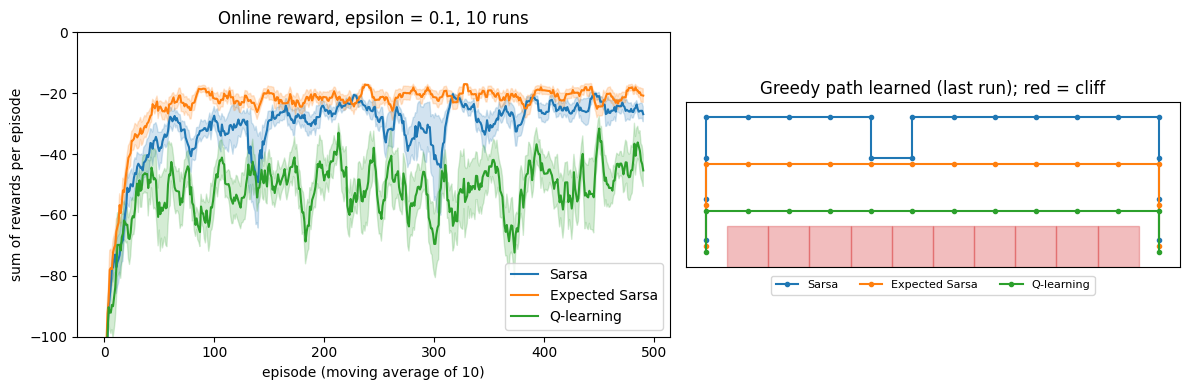

Sarsa greedy policy:
>>>>v>>>>>>v
^>^>>^^^^v>v
^^>^<^^^^>^v
^CCCCCCCCCCG

Expected Sarsa greedy policy:
>>>>>>>>>>>v
>>>>>>>>>>>v
^^^^^^^^^^>v
^CCCCCCCCCCG

Q-learning greedy policy:
^^>>^>>>>>vv
>vv>>>>v>>vv
>>>>>>>>>>>v
^CCCCCCCCCCG



In [6]:
out = experiment_cliff_walking.run(runs=10, episodes=500)
for name, row in out["summary"].items():
    if isinstance(row, dict):
        print(f"{name:15s} online reward (last 100 episodes) = {row['online_reward_last_100']:6.1f} | "
              f"greedy return = {row['greedy_return_mean']:6.1f} ({row['greedy_reached_goal']} of 10 runs reach G)")
plt.show()
for name, q in out["q"].items():
    print(f"{name} greedy policy:\n{out['env'].render_policy(TabularPolicy.greedy(q).table)}\n")

> **Code.** Maximization bias in its simplest form: every action has true value $0$, each estimate is a mean of 5 noisy rewards. $\max_a Q(a)$ is biased upward and the bias grows with the number of actions; the double estimator (select with one half of the data, evaluate with the other) removes this bias here, at the cost of its own variance.

In [7]:
for n_actions in (2, 10, 50):
    single, double = single_and_double_estimates(n_actions, n_samples=5, n_trials=20_000)
    print(f"{n_actions:3d} actions: E[max_a Q(a)] = {single.mean():+.3f} | double estimator = {double.mean():+.3f} | true = 0")

  2 actions: E[max_a Q(a)] = +0.177 | double estimator = -0.003 | true = 0
 10 actions: E[max_a Q(a)] = +0.486 | double estimator = -0.008 | true = 0


 50 actions: E[max_a Q(a)] = +0.711 | double estimator = -0.003 | true = 0


## 6. Exercises

1. Keep the example but $\pi(L \mid u) = 0.5$, $A_{t+1} = L$. Compute the three targets and the three new estimates.
2. Is a fixed $\epsilon$-greedy $0.1$ GLIE?
3. An action never seen in the dataset but with a large $Q$: does the tabular theorem guarantee that this estimate is correct?

In [8]:
for name, (y, q_new) in worked_example(pi_L=0.5, sampled="L").items():
    print(f"Exercise 1, {name:15s} target = {y:.2f}   new Q(s,a) = {q_new:.2f}")
print("Exercise 2: constant schedule at episode 10^6 ->", EpsilonSchedule.constant(0.1)(10**6), "(does not go to 0)")

Exercise 1, Sarsa           target = 4.60   new Q(s,a) = 3.30
Exercise 1, Expected Sarsa  target = 2.80   new Q(s,a) = 2.40
Exercise 1, Q-learning      target = 4.60   new Q(s,a) = 3.30
Exercise 2: constant schedule at episode 10^6 -> 0.1 (does not go to 0)


<details>
<summary><b>Answers (Appendix A)</b></summary>

(1) Sarsa target $4.6$, estimate $3.3$; Expected Sarsa target $2.8$, estimate $2.4$; Q-learning target $4.6$, estimate $3.3$. (2) No: a fixed $\epsilon$ is not greedy in the limit; infinite visitation also needs its own proof. (3) No: the theorem requires coverage, it does not apply to a pair that has never been learned.
</details>

## 7. Remember and read further

Sarsa uses the sampled future action; Expected Sarsa takes the expectation; Q-learning uses the max. Off-policy is a relationship between policies. Read Silver 5 and Sutton–Barto §§6.4–6.7.